# EDA: time

`updated_at` is the one timestamp every row has. It is the time of the *last edit* of a list
entry, not the time the anime was watched. This notebook checks what that timestamp can and
cannot support: a train / test split by date, recency features, and watch order.

Inputs: `tables/monthly_activity.csv`, `tables/lag_after_start.csv`,
`data/clean/users.parquet`, `data/eda/user_stats.parquet` and the 1% user sample
`data/eda/sample_ratings.parquet`.

In [1]:
import sys
from datetime import date
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[1]))

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from cleaning import config, plotting
from cleaning.plotting import AQUA, BLUE, MUTED, ORANGE

plotting.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(12)

COHORTS = ["collector", "kaggle_2022", "legacy_2025"]
COLOR = dict(zip(COHORTS, (BLUE, ORANGE, AQUA)))

monthly = pl.read_csv(config.TABLES / "monthly_activity.csv", try_parse_dates=True)
lag = pl.read_csv(config.TABLES / "lag_after_start.csv")
users = pl.read_parquet(config.CLEAN_USERS).drop("username").join(
    pl.read_parquet(config.USER_STATS), on="user_id", how="left")
sample = pl.read_parquet(config.SAMPLE_RATINGS)
anime = pl.read_parquet(config.CLEAN_ANIME, columns=["anime_id", "start_date", "start_precision"])
print(f"{monthly['n'].sum():,} rows with a timestamp, from {monthly['month'].min()} to {monthly['month'].max()}")

548,924,923 rows with a timestamp, from 2004-07-01 to 2026-10-01


## 1. When list entries were last edited

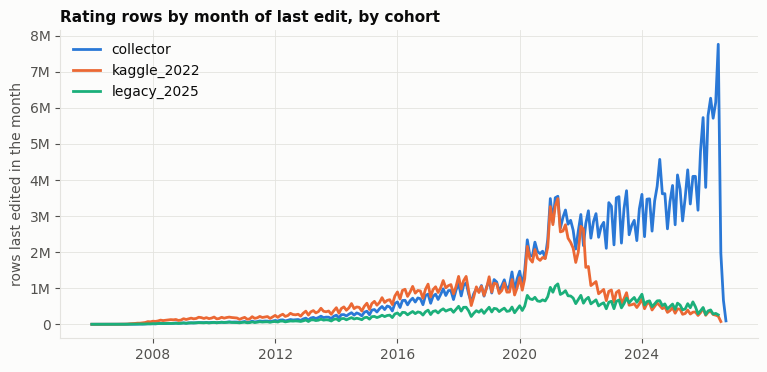

rows edited on or after 2025-01-01: 18.7%
rows edited on or after 2025-07-01: 14.0%
rows edited on or after 2026-01-01: 8.8%
of completed + watching rows: {'2025-01-01': '18.3%', '2025-07-01': '13.7%', '2026-01-01': '8.6%'}


In [2]:
by = monthly.filter(pl.col("month") >= date(2006, 1, 1)).group_by("cohort", "month").agg(pl.col("n").sum()).sort("month")
fig, ax = plt.subplots(figsize=(9, 4))
for cohort in COHORTS:
    c = by.filter(pl.col("cohort") == cohort)
    ax.plot(c["month"], c["n"], color=COLOR[cohort], label=cohort)
ax.set_ylabel("rows last edited in the month"); ax.set_title("Rating rows by month of last edit, by cohort")
plotting.thousands(ax)
ax.legend()
plt.show()
total = monthly["n"].sum()
for t in config.TIME_SPLITS:
    print(f"rows edited on or after {t}: {monthly.filter(pl.col('month') >= t)['n'].sum() / total:.1%}")
watched = monthly.filter(pl.col("status").is_in(config.WATCHED))
print("of completed + watching rows:", {str(t): f"{watched.filter(pl.col('month') >= t)['n'].sum() / watched['n'].sum():.1%}"
                                        for t in config.TIME_SPLITS})

An entry keeps only its last edit, so old months are thinned out: an anime completed in 2015
and re-scored in 2024 counts in 2024. With that caveat, 14% of all rows were last edited on or
after 2025-07-01 and 9% in 2026. The cohorts live in different periods: `kaggle_2022` activity
collapses after 2022, when that username list was made, while `collector` users (found online
in 2026) dominate everything recent. The final drop is the end of the crawl: each user's list
is frozen at their crawl date, between July and early October 2026.

## 2. When users were last active

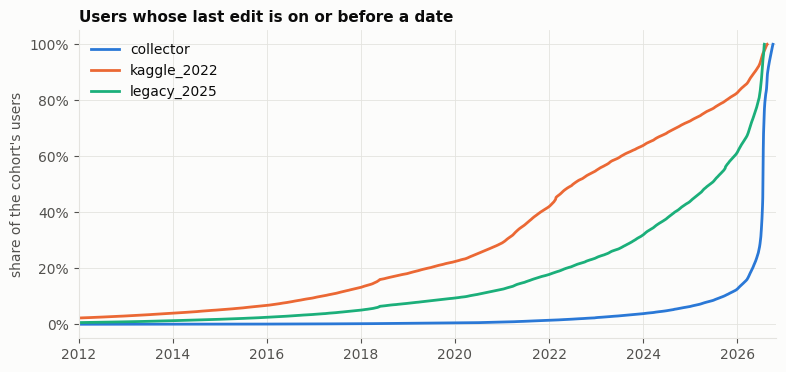

shape: (3, 6)
┌─────────────┬────────┬───────────────────┬───────────────────┬──────────────────┬────────────────┐
│ cohort      ┆ users  ┆ inactive since    ┆ inactive since    ┆ inactive since   ┆ active in 2026 │
│ ---         ┆ ---    ┆ 2025-01-01        ┆ 2025-07-01        ┆ 2026-01-01       ┆ ---            │
│ str         ┆ u32    ┆ ---               ┆ ---               ┆ ---              ┆ f64            │
│             ┆        ┆ f64               ┆ f64               ┆ f64              ┆                │
╞═════════════╪════════╪═══════════════════╪═══════════════════╪══════════════════╪════════════════╡
│ collector   ┆ 952667 ┆ 0.064             ┆ 0.086             ┆ 0.125            ┆ 0.875          │
│ kaggle_2022 ┆ 738285 ┆ 0.726             ┆ 0.772             ┆ 0.826            ┆ 0.174          │
│ legacy_2025 ┆ 216306 ┆ 0.439             ┆ 0.51              ┆ 0.613            ┆ 0.387          │
└─────────────┴────────┴───────────────────┴───────────────────┴─────────────

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
for cohort in COHORTS:
    last = users.filter((pl.col("cohort") == cohort) & pl.col("last_update").is_not_null())["last_update"].sort()
    ax.plot(last.to_numpy(), np.arange(1, last.len() + 1) / last.len(), color=COLOR[cohort], label=cohort)
ax.set_xlim(np.datetime64("2012-01-01"), np.datetime64("2026-11-01"))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylabel("share of the cohort's users"); ax.set_title("Users whose last edit is on or before a date")
ax.legend()
plt.show()
print(users.group_by("cohort").agg(
    pl.len().alias("users"),
    *[(pl.col("last_update") < pl.lit(t)).mean().round(3).alias(f"inactive since {t}") for t in config.TIME_SPLITS],
    (pl.col("last_update").dt.year() == 2026).mean().round(3).alias("active in 2026"),
).sort("users", descending=True))

77% of `kaggle_2022` users and 51% of `legacy_2025` users have no edit after 2025-07-01,
against 9% of `collector` users. Recent behaviour in this dataset is almost entirely the
behaviour of the collector cohort.

## 3. A date split: who can be evaluated?

For a cut date T, a user can be evaluated when they have enough watched anime before T to
build a history and at least some after T to predict.

shape: (12, 8)
┌─────────────┬─────────────┬─────────┬────────┬────────────┬────────────┬────────────┬────────────┐
│ cut date    ┆ cohort      ┆ users   ┆ >=10   ┆ >=10       ┆ >=10       ┆ only after ┆ eligible   │
│ ---         ┆ ---         ┆ ---     ┆ before ┆ before,    ┆ before,    ┆ (new user) ┆ users (>=5 │
│ str         ┆ str         ┆ i64     ┆ ---    ┆ >=1 after  ┆ >=5 after  ┆ ---        ┆ after)     │
│             ┆             ┆         ┆ f64    ┆ ---        ┆ ---        ┆ f64        ┆ ---        │
│             ┆             ┆         ┆        ┆ f64        ┆ f64        ┆            ┆ i64        │
╞═════════════╪═════════════╪═════════╪════════╪════════════╪════════════╪════════════╪════════════╡
│ 2025-01-01  ┆ collector   ┆ 952667  ┆ 0.666  ┆ 0.607      ┆ 0.552      ┆ 0.276      ┆ 525487     │
│ 2025-01-01  ┆ kaggle_2022 ┆ 738285  ┆ 0.917  ┆ 0.257      ┆ 0.179      ┆ 0.002      ┆ 132188     │
│ 2025-01-01  ┆ legacy_2025 ┆ 216306  ┆ 0.886  ┆ 0.48       ┆ 0.388      ┆ 0

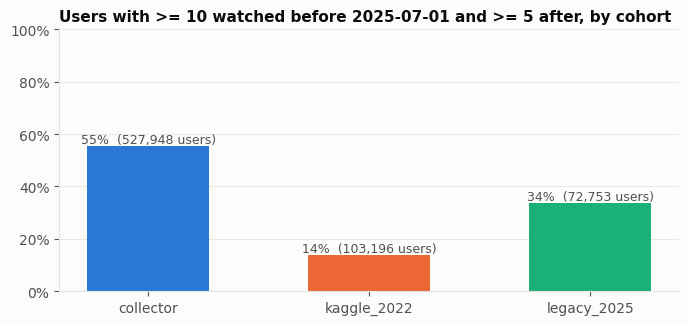

In [4]:
rows = []
for t in config.TIME_SPLITS:
    before, after = pl.col(f"n_watched_before_{t}"), pl.col(f"n_watched_from_{t}")
    for cohort in COHORTS + ["all"]:
        u = users if cohort == "all" else users.filter(pl.col("cohort") == cohort)
        rows.append({
            "cut date": str(t), "cohort": cohort, "users": u.height,
            ">=10 before": u.select((before >= 10).mean()).item(),
            ">=10 before, >=1 after": u.select(((before >= 10) & (after >= 1)).mean()).item(),
            ">=10 before, >=5 after": u.select(((before >= 10) & (after >= 5)).mean()).item(),
            "only after (new user)": u.select(((before == 0) & (after >= 1)).mean()).item(),
            "eligible users (>=5 after)": u.select(((before >= 10) & (after >= 5)).sum()).item(),
        })
split = pl.DataFrame(rows)
print(split.with_columns(pl.col(pl.Float64).round(3)))

t = config.TIME_SPLITS[1]
fig, ax = plt.subplots(figsize=(8, 3.4))
s = split.filter((pl.col("cut date") == str(t)) & (pl.col("cohort") != "all"))
bars = ax.bar(s["cohort"], s[">=10 before, >=5 after"], color=[COLOR[c] for c in s["cohort"]], width=0.55)
ax.bar_label(bars, labels=[f"{v:.0%}  ({n:,} users)" for v, n in zip(s[">=10 before, >=5 after"], s["eligible users (>=5 after)"])],
             color=MUTED, fontsize=9)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_ylim(0, 1); ax.grid(axis="x", visible=False)
ax.set_title(f"Users with >= 10 watched before {t} and >= 5 after, by cohort")
plt.show()

With a cut at 2025-07-01, 704k users have at least 10 watched anime before the cut and at
least 5 after it, and three quarters of them (528k) are collector users. Only 14% of
`kaggle_2022` users qualify: most of that cohort can serve as training history but not as
evaluation users. Moving the cut changes the totals little (742k for 2025-01-01, 620k for
2026-01-01). Separately, 12% of users have nothing before the cut and something after it: new
accounts, which a date split turns into cold-start users.

## 4. How soon after release do users add an anime?

Completed and watching entries, for anime whose start date is known to the day:
time between the anime's start date and the entry's last edit.

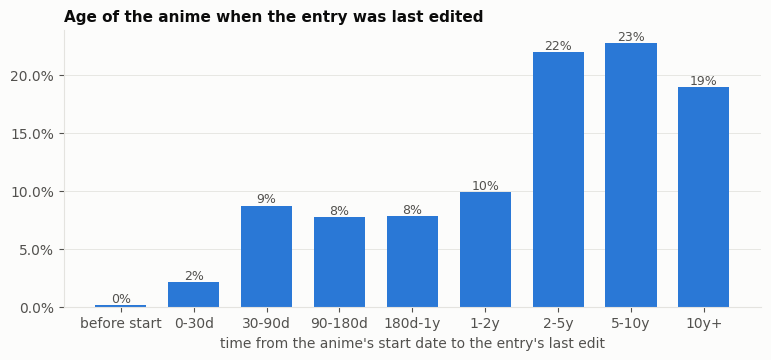

shape: (9, 4)
┌──────────────┬───────────┬─────────────┬─────────────┐
│ lag          ┆ collector ┆ kaggle_2022 ┆ legacy_2025 │
│ ---          ┆ ---       ┆ ---         ┆ ---         │
│ str          ┆ f64       ┆ f64         ┆ f64         │
╞══════════════╪═══════════╪═════════════╪═════════════╡
│ before start ┆ 0.001     ┆ 0.001       ┆ 0.001       │
│ 0-30d        ┆ 0.023     ┆ 0.019       ┆ 0.021       │
│ 30-90d       ┆ 0.098     ┆ 0.07        ┆ 0.079       │
│ 90-180d      ┆ 0.082     ┆ 0.071       ┆ 0.071       │
│ 180d-1y      ┆ 0.076     ┆ 0.083       ┆ 0.077       │
│ 1-2y         ┆ 0.094     ┆ 0.108       ┆ 0.099       │
│ 2-5y         ┆ 0.206     ┆ 0.244       ┆ 0.22        │
│ 5-10y        ┆ 0.223     ┆ 0.236       ┆ 0.232       │
│ 10y+         ┆ 0.197     ┆ 0.169       ┆ 0.201       │
└──────────────┴───────────┴─────────────┴─────────────┘


In [5]:
labels = ["before start", "0-30d", "30-90d", "90-180d", "180d-1y", "1-2y", "2-5y", "5-10y", "10y+"]
all_lag = lag.group_by("lag").agg(pl.col("n").sum())
share = {r[0]: r[1] / all_lag["n"].sum() for r in all_lag.rows()}
fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.bar(labels, [share.get(k, 0) for k in labels], color=BLUE, width=0.7)
ax.bar_label(bars, labels=[f"{share.get(k, 0):.0%}" for k in labels], color=MUTED, fontsize=9)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax.grid(axis="x", visible=False)
ax.set_xlabel("time from the anime's start date to the entry's last edit")
ax.set_title("Age of the anime when the entry was last edited")
plt.show()
by_cohort = lag.group_by("cohort", "lag").agg(pl.col("n").sum()).with_columns(
    share=pl.col("n") / pl.col("n").sum().over("cohort"))
print(by_cohort.pivot("cohort", index="lag", values="share").with_columns(pl.exclude("lag").round(3))
      .sort(pl.col("lag").replace_strict({k: i for i, k in enumerate(labels)}, return_dtype=pl.Int32)))

Most watching is back catalog: about a quarter of watched entries were last edited within a
year of the anime's start, and about 40% five or more years after it (part of that is late
edits of old entries). The three cohorts look alike. For a recommender this means the
candidate set cannot be limited to recent seasons.

## 5. Can `updated_at` order a user's history?

If a user edits hundreds of entries on one day (an import, a clean-up), those entries carry
no order. The chart shows, per user, the share of the timestamped list that falls on the
user's single busiest day.

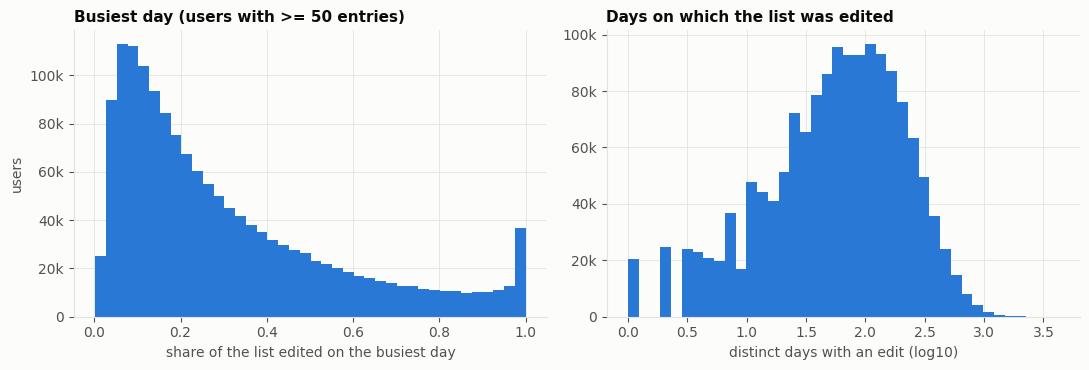

busiest day holds at least 25% of the list: 45.8% of users
busiest day holds at least 50% of the list: 20.5% of users
busiest day holds at least 90% of the list: 4.7% of users
median distinct edit days 63; median entries per edit day 3.5


shape: (3, 3)
┌─────────────┬────────────────────────────┬──────────────────┐
│ cohort      ┆ busiest day >= 50% of list ┆ median edit days │
│ ---         ┆ ---                        ┆ ---              │
│ str         ┆ f64                        ┆ f64              │
╞═════════════╪════════════════════════════╪══════════════════╡
│ kaggle_2022 ┆ 0.211                      ┆ 50.0             │
│ legacy_2025 ┆ 0.179                      ┆ 77.0             │
│ collector   ┆ 0.206                      ┆ 74.0             │
└─────────────┴────────────────────────────┴──────────────────┘


In [6]:
u = users.filter(pl.col("n_ratings") >= 50).with_columns(
    top_day=pl.col("max_rows_per_day") / pl.col("n_ratings"),
    rows_per_day=pl.col("n_ratings") / pl.col("n_update_days"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(u["top_day"].drop_nulls(), bins=40, color=BLUE)
axes[0].set_xlabel("share of the list edited on the busiest day"); axes[0].set_ylabel("users")
axes[0].set_title("Busiest day (users with >= 50 entries)")
plotting.thousands(axes[0])
axes[1].hist(np.log10(u["n_update_days"].drop_nulls().to_numpy()), bins=40, color=BLUE)
axes[1].set_xlabel("distinct days with an edit (log10)"); axes[1].set_title("Days on which the list was edited")
plotting.thousands(axes[1])
plt.tight_layout()
plt.show()
for x in (0.25, 0.5, 0.9):
    print(f"busiest day holds at least {x:.0%} of the list: {(u['top_day'] >= x).mean():.1%} of users")
print(f"median distinct edit days {u['n_update_days'].median():.0f}; median entries per edit day {u['rows_per_day'].median():.1f}")
print(u.group_by("cohort").agg((pl.col("top_day") >= 0.5).mean().round(3).alias("busiest day >= 50% of list"),
                               pl.col("n_update_days").median().alias("median edit days")))

In [7]:
s = (sample.filter(pl.col("status").is_in(config.WATCHED) & pl.col("updated_at").is_not_null())
           .with_columns(day=pl.col("updated_at").dt.date())
           .with_columns(same_day=pl.len().over("user_id", "day")))
print(f"sample: {s['user_id'].n_unique():,} users, {s.height:,} watched rows with a timestamp")
for k in (1, 5, 20, 100):
    print(f"  watched rows edited on a day with more than {k:>3} other watched rows of the same user: "
          f"{(s['same_day'] > k).mean():.1%}")

sample: 18,875 users, 3,772,739 watched rows with a timestamp
  watched rows edited on a day with more than   1 other watched rows of the same user: 77.7%
  watched rows edited on a day with more than   5 other watched rows of the same user: 52.2%
  watched rows edited on a day with more than  20 other watched rows of the same user: 37.5%
  watched rows edited on a day with more than 100 other watched rows of the same user: 16.9%


Edits are bursty. For a fifth of the users with at least 50 entries a single day holds half of
the list or more, and for 46% it holds a quarter. In the sample, 38% of watched rows were
edited on a day when the same user edited more than 20 other watched rows. So `updated_at`
orders a user's *sessions* for most users, but not the entries within a session, and for
roughly one user in five it gives almost no order at all. A sequence model has to tolerate ties
(treat a day as a set) or be trained and evaluated on users whose edits are spread out. A date
split is unaffected: it only needs to know which side of the cut a row is on.

## 6. Do users watch recent anime?

Sample rows that are completed, by year of last edit: how old the anime was at that time.

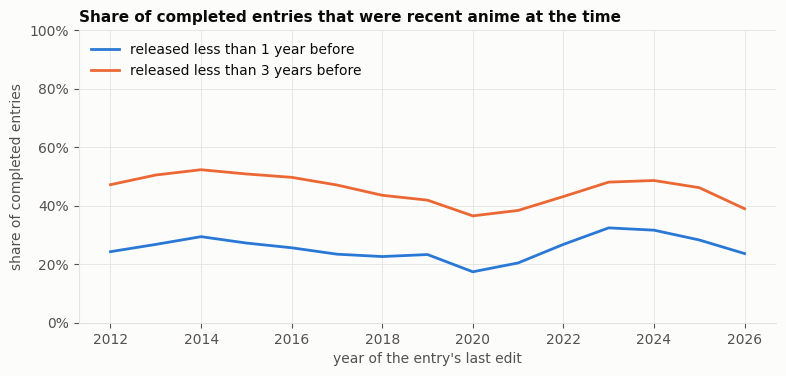

shape: (15, 5)
┌──────┬────────┬────────────┬──────────────┬───────────────┐
│ year ┆ rows   ┆ median age ┆ under 1 year ┆ under 3 years │
│ ---  ┆ ---    ┆ ---        ┆ ---          ┆ ---           │
│ i32  ┆ u32    ┆ f64        ┆ f64          ┆ f64           │
╞══════╪════════╪════════════╪══════════════╪═══════════════╡
│ 2012 ┆ 37069  ┆ 3.318      ┆ 0.243        ┆ 0.472         │
│ 2013 ┆ 53823  ┆ 2.951      ┆ 0.268        ┆ 0.505         │
│ 2014 ┆ 70355  ┆ 2.765      ┆ 0.294        ┆ 0.523         │
│ 2015 ┆ 106855 ┆ 2.919      ┆ 0.272        ┆ 0.508         │
│ 2016 ┆ 141838 ┆ 3.036      ┆ 0.256        ┆ 0.497         │
│ 2017 ┆ 163958 ┆ 3.296      ┆ 0.234        ┆ 0.471         │
│ 2018 ┆ 173337 ┆ 3.655      ┆ 0.226        ┆ 0.436         │
│ 2019 ┆ 192975 ┆ 3.888      ┆ 0.233        ┆ 0.419         │
│ 2020 ┆ 341035 ┆ 4.6        ┆ 0.174        ┆ 0.365         │
│ 2021 ┆ 505025 ┆ 4.561      ┆ 0.204        ┆ 0.384         │
│ 2022 ┆ 364093 ┆ 3.934      ┆ 0.268        ┆ 0.431    

In [8]:
c = (sample.filter((pl.col("status") == "completed") & pl.col("updated_at").is_not_null())
           .join(anime.filter(pl.col("start_precision") == "day")
                      .select("anime_id", pl.col("start_date").alias("released")), on="anime_id")
           .with_columns(year=pl.col("updated_at").dt.year(),
                         age=(pl.col("updated_at").dt.date() - pl.col("released")).dt.total_days() / 365.25)
           .filter(pl.col("year") >= 2012))
by_year = c.group_by("year").agg(pl.len().alias("rows"), pl.col("age").median().alias("median age"),
                                 (pl.col("age") < 1).mean().alias("under 1 year"),
                                 (pl.col("age") < 3).mean().alias("under 3 years")).sort("year")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(by_year["year"], by_year["under 1 year"], color=BLUE, label="released less than 1 year before")
ax.plot(by_year["year"], by_year["under 3 years"], color=ORANGE, label="released less than 3 years before")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax.set_ylim(0, 1)
ax.set_xlabel("year of the entry's last edit"); ax.set_ylabel("share of completed entries")
ax.set_title("Share of completed entries that were recent anime at the time")
ax.legend(loc="upper left")
plt.show()
print(by_year.with_columns(pl.col(pl.Float64).round(3)))

In every year, a quarter to a third of the anime users complete were released less than a year
earlier and close to half less than three years earlier; the median completed anime is 3 to 5
years old. The dip in 2020-2021 is the wave of new users of those years working through older
titles. One year of releases is about 4% of the catalog, so recent anime are heavily
over-represented and recency is a strong feature. Still, more than half of what people watch
is older than three years.